In [2]:
import pandas as pd
from astropy.io import fits
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
import subprocess
import os
from math import sin, cos, tan, radians, sqrt, pi
from os.path import join
from matplotlib.pylab import *
from astropy.wcs import WCS
from scipy import stats
from scipy.stats import ks_2samp
import seaborn as sns

In [60]:
# Initialisation and parameters
# Defines inputs
# Run fearlessly

cat_csv = pd.read_csv("/Users/kyriakos.trakakis/Downloads/Other_Stuff/ATLASGAL_CSC_distances.csv")  # Example CSV

cat_csv = cat_csv[
    (cat_csv['gal_long_peak'] >= 198) & 
    (cat_csv['gal_long_peak'] <= 236)
].reset_index(drop=True)

region       = "227-236"
v_lim        = 3
minor_lim    = 69

has_COLTE = 'True'

mult_path = f"/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/FGN/12CO/"
#mult_path = f"/Users/kyriakos.trakakis/Downloads/FUGIN_data/13CO/"

cat_csv['V_lsr'] = pd.to_numeric(cat_csv['V_lsr'], errors='coerce')
cat_csv = cat_csv.dropna(subset=['gal_long_peak', 'gal_lat_peak', 'V_lsr']).reset_index(drop=True)

input_filename  = f"FGN_{region}_12CO_23arcsec_SNR_spline_min_del_2_parallel_clusters.fits"
#input_filename  = f"FGN_13CO_{region}_23arcsec_SNR_spline_min_del_2_parallel_clusters.fits"
mult_filename   = mult_path +f"FGN_{region}_12CO_23arcsec.fits"
#mult_filename   = mult_path +f"FGN_13CO_{region}_23arcsec_trimmed.fits"
COLTE_N13_file  = f"/Users/kyriakos.trakakis/COLTE/colte_FGN_{region}_23arcsec_N13CO.fits"

clusters_path     = '/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/FGN/12CO/'
clusters_file     = f"FGN_{region}_12CO_23arcsec_SNR_spline_min_del_2_parallel_clusters_table.fits"
#clusters_file     = f"FGN_13CO_{region}_23arcsec_SNR_spline_min_del_2_parallel_clusters_table.fits"
csv_output        = mult_path +f"FGN_13CO_{region}_vrms_3_X_factor_masses_spline.csv"
table             = Table.read(clusters_path + clusters_file, format='fits')

df = table.to_pandas()


# --- Load original data ---
with fits.open(os.path.join(clusters_path, input_filename)) as hdul:
    data = hdul[0].data  # Clusters
    header = hdul[0].header
    
CDELT3 = header['CDELT3']

df = df[(df["minor_arcsec"] > minor_lim / 2.354) & (df["sigv_kms"] > v_lim / 2.354)]


df = df.drop(['luminosity', 'volume', 'flux'], axis = 1)


l_atlasgal = cat_csv['gal_long_peak']
b_atlasgal = cat_csv['gal_lat_peak']
v_atlasgal = cat_csv['V_lsr']
d_atlasgal = cat_csv['distance']


# FITS (GRS) example
l_fgn = df['x_cen']
b_fgn = df['y_cen']
v_fgn = df['v_cen'] / 1000
angle = df['position_angle']

dl = np.maximum(df['major_arcsec'] / 3600 * abs(np.cos(angle*np.pi/180)), df['minor_arcsec'] * abs(np.sin(angle*np.pi/180)) / 3600) / 2 * 2.354
db = np.maximum(df['major_arcsec'] / 3600 * abs(np.sin(angle*np.pi/180)), df['minor_arcsec'] * abs(np.cos(angle*np.pi/180)) / 3600) / 2 * 2.354
dv = df['sigv_kms'] / 2 * 2.354  # Or define your own constant window like ±1 km/s

In [61]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,sigv_kms,xcens,ycens,vcens,major_arcsec,minor_arcsec,parent,ancestor,n_leaves,structure_type
4,35,15593.850117,27731.0,97.416487,36.755553,169.449503,59.838088,18093.467770,2.836145,233.081490,...,1.843494,233.081490,0.177216,18093.467770,828.040138,312.422197,24,8,5,b'B'
12,94,691.691716,1422.0,16.992447,9.346709,64.433351,12.602518,21543.475701,2.486464,234.897158,...,1.616201,234.897158,0.523458,21543.475701,144.435803,79.447024,-1,94,3,b'T'
23,255,674.863010,2131.0,15.221981,10.179970,137.858688,12.448266,43347.135113,2.414690,234.201688,...,1.569549,234.201688,-0.227400,43347.135113,129.386840,86.529747,215,229,7,b'B'
25,267,1926.686744,3652.0,24.237503,18.252624,-150.154222,21.033260,43149.256478,2.115020,233.018188,...,1.374763,233.018188,-0.371854,43149.256478,206.018776,155.147300,-1,267,3,b'T'
33,318,302.979287,538.0,11.984552,5.804879,84.449455,8.340796,44021.222788,2.255512,234.812838,...,1.466083,234.812838,-0.029976,44021.222788,101.868691,49.341475,257,229,2,b'B'
37,377,1506.527231,3796.0,33.170746,10.428547,145.749249,18.598997,46874.355037,2.245387,234.692391,...,1.459501,234.692391,0.893274,46874.355037,281.951342,88.642651,-1,377,6,b'T'
38,398,2207.281608,3568.0,42.325632,11.974472,55.418533,22.512820,46806.564082,2.407123,234.484270,...,1.564630,234.484270,0.869728,46806.564082,359.767872,101.783008,-1,398,6,b'T'
45,525,1852.138419,3130.0,29.070286,14.629389,120.287684,20.622331,76301.998690,2.460994,234.316965,...,1.599646,234.316965,-0.856909,76301.998690,247.097434,124.349808,-1,525,6,b'T'


In [62]:
# Runs section 1, Atlasgal matcher rectangles
# Saves an output

# --- Match sources ---
matches = []

for i in range(len(df)):
    for j in range(len(cat_csv)):
        if (abs(l_atlasgal.iloc[j] - l_fgn.iloc[i]) <= dl.iloc[i] and
            abs(b_atlasgal.iloc[j] - b_fgn.iloc[i]) <= db.iloc[i] and
            abs(v_atlasgal.iloc[j] - v_fgn.iloc[i]) <= dv.iloc[i]):
            matches.append({
                'fgn_index': df['_idx'].iloc[i],
                'atlasgal_name': cat_csv['atlas_name'].iloc[j],  # or gname_jps
                'l_atlasgal': l_atlasgal.iloc[j],
                'b_atlasgal': b_atlasgal.iloc[j],
                'v_atlasgal': v_atlasgal.iloc[j],
                'l_fgn': round(l_fgn.iloc[i],2),
                'b_fgn': round(b_fgn.iloc[i],2),
                'v_fgn': round(v_fgn.iloc[i],2),
                'l_distance': round((l_atlasgal.iloc[j] - l_fgn.iloc[i]) / dl.iloc[i],2),
                'b_distance': round((b_atlasgal.iloc[j] - b_fgn.iloc[i]) / db.iloc[i],2),
                'v_distance': round((v_atlasgal.iloc[j] - v_fgn.iloc[i]) / dv.iloc[i],2),
                'distance': d_atlasgal.iloc[j]
            })

# Now extract all matched _idx values
matched_ids = {match['fgn_index'] for match in matches}

# Add a 'has_match' column to df
df['has_match'] = df['_idx'].isin(matched_ids)

df_matches = pd.DataFrame(matches)
print(df_matches)
#df_matches.to_csv("FGN_37_47_matched_sources_test.csv", index=False)

if df_matches.empty:
    most_common_distances = pd.DataFrame(columns=['fgn_index','most_common_distance'])
else:
    most_common_distances = (
        df_matches.groupby('fgn_index')['distance']
        .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
        .reset_index()
        .rename(columns={'distance': 'most_common_distance'})
    )

#most_common_distances = (
#    df_matches.groupby('mopra_index')['distance']
#    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
#    .reset_index()
#    .rename(columns={'distance': 'most_common_distance'})
#)

print(most_common_distances)

# Merge most_common_distance into the main DataFrame on 'mopra_index' and '_idx'
df = df.merge(most_common_distances, how='left', left_on='_idx', right_on='fgn_index')

# Fill NaN (i.e., unmatched sources) with 0
df['AGAL_distance'] = df['most_common_distance'].fillna(0)

# Optionally drop the 'mopra_index' and 'most_common_distance' columns if not needed
df = df.drop(columns=['fgn_index', 'most_common_distance'])


Empty DataFrame
Columns: []
Index: []
Empty DataFrame
Columns: [fgn_index, most_common_distance]
Index: []


In [63]:
# Convert to Pandas DataFrame and add distance inputs
# Run fearlessly


cluster_ids = df['_idx']
cluster_ids = cluster_ids.to_numpy()

df_inp = pd.DataFrame({
    'Source'       : df['_idx'],
    'Long (deg)'   : df['x_cen'],
    'Lat (deg)'    : df['y_cen'],
    'vlsr (km/s)'  : df['v_cen']/1000,
    'v_rms (km/s)' : df['v_rms']/1000,
    'P': 0.5
})

In [64]:
# Creates the sources.info file in v2.4.1
# Saves necessary file

# Save to .inp file with space-separated columns
output_path = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
output_file = 'sources_info.inp'

with open(output_path+output_file, 'w') as f:
    f.write('! Source Long(deg) Lat(deg) vlsr(km/s) v_rms(km/s) P\n')  # comment line
    df_inp.to_csv(f, sep=' ', index=False, header=False, float_format='%.4f')


# Path to the Fortran executable
exe_path = "/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/distance_calculator"
distance_dir='/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
os.chdir(distance_dir)

try:
    result = subprocess.run([exe_path], check=True, capture_output=True, text=True)
    print("Program output:")
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("Error running Fortran program:")
    print(e.stderr)

Program output:
 Bayesian distance estimator: 2019: September 24, 2019

 Reading in file "probability_controls.inp                        "
 Max Prob_SA = 0.85
 Max Prob_KD = 0.85
 Max Prob_GL = 0.85
 Max Prob_PS = 0.15
 Max Prob_PM = 0.85


 Openning input ascii file "galaxy_data_Univ.inp            "
 Comment lines follow:
 ! Galactic and Solar Motion parameters                                          
 ! for use with 2-parameter Persic "Universal" rotation curve                    
 End of Comment lines

 Galaxy model:
  Ro, a1, a2, a3:                         8.15   236.000     0.960     1.620
  Solar Motion (Uo,Vo,Wo):               10.60     10.70      7.60
  Source Peculiar Motion (Us,Vs,Ws):      0.00      0.00      0.00

 Getting Spiral arm segment data:
 

  Read file Out_lbvRBD.2019      containing 176 (l,b,v,R,beta,D) values.
       Spanning longitude range:    0.0 to  252.0 deg.

  Read file Per_lbvRBD.2019      containing 272 (l,b,v,R,beta,D) values.
       Spanning long

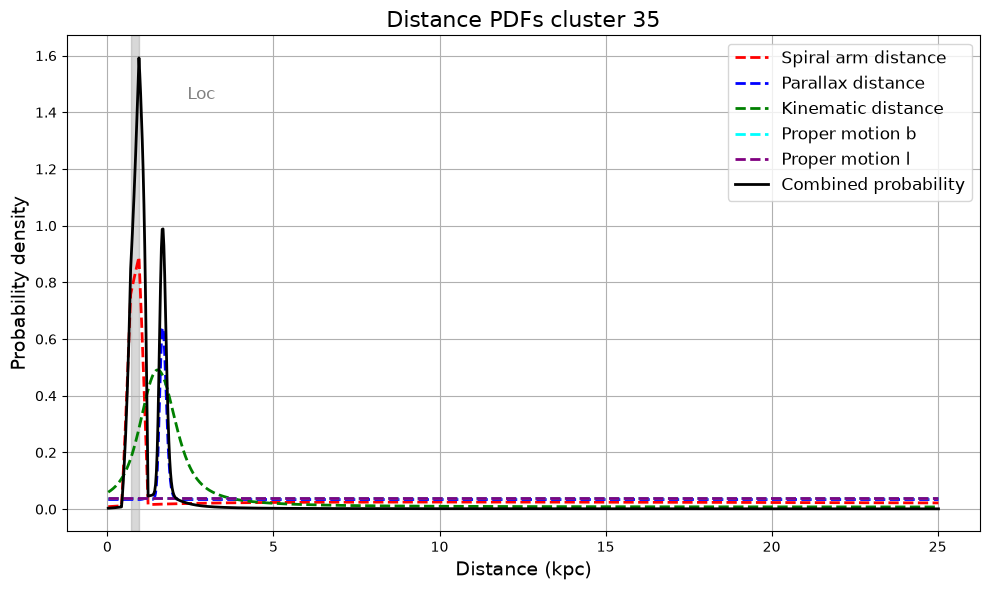

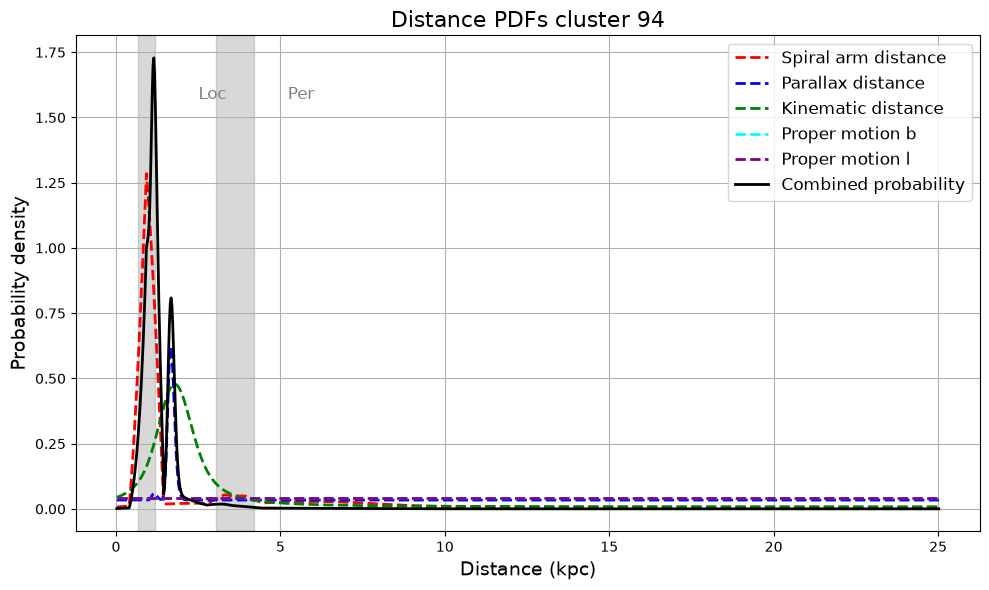

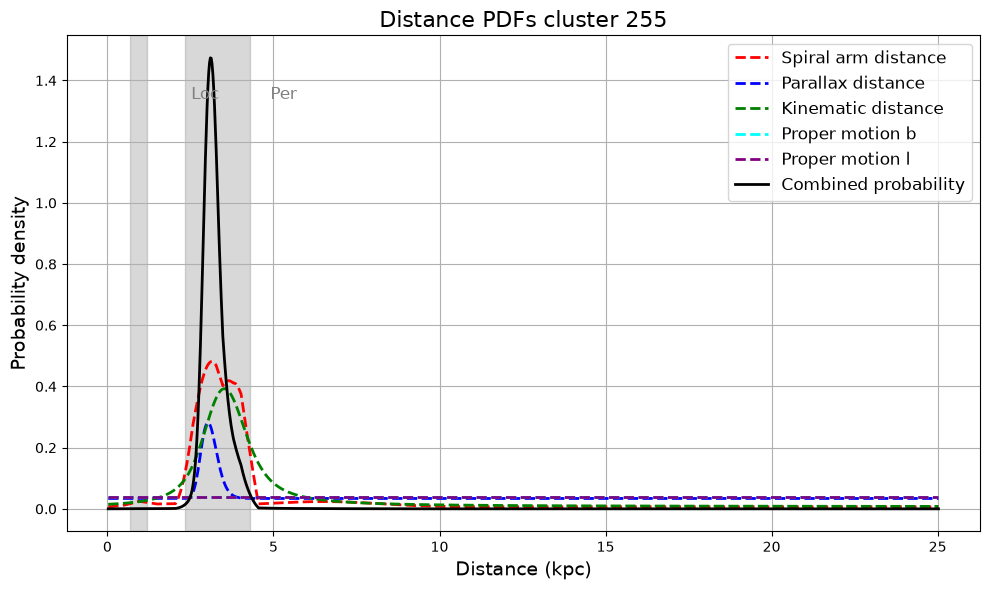

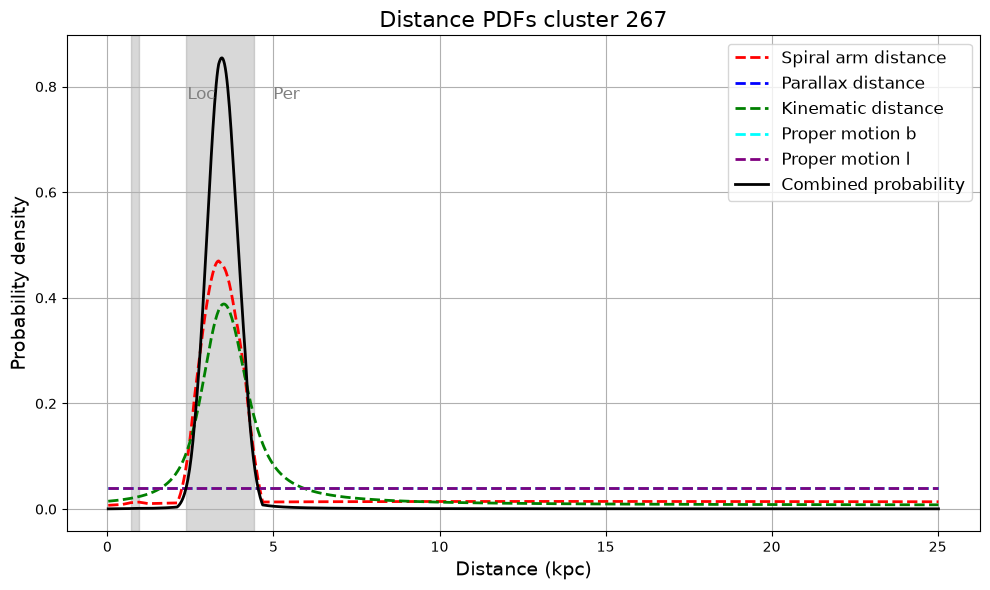

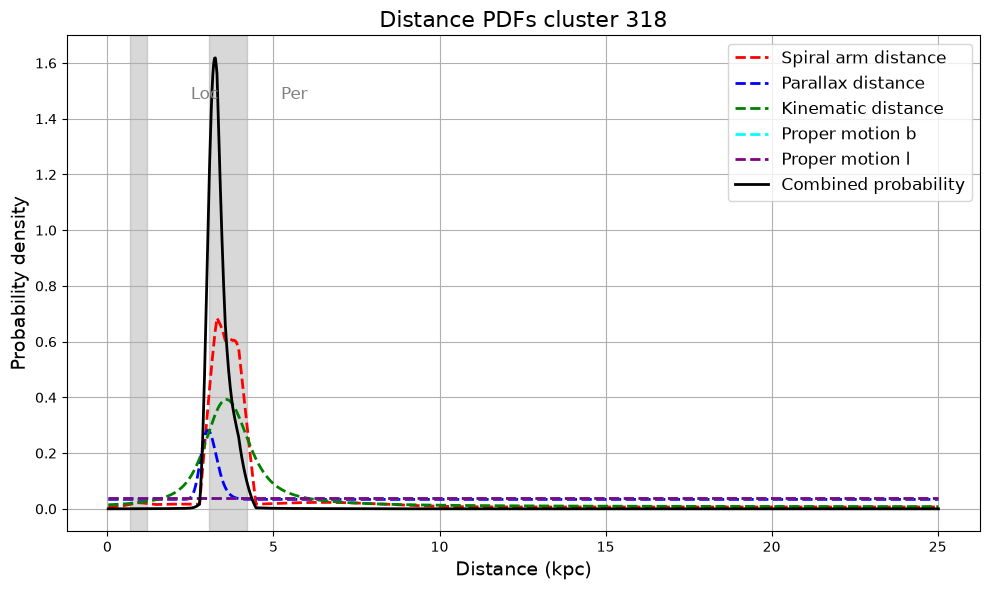

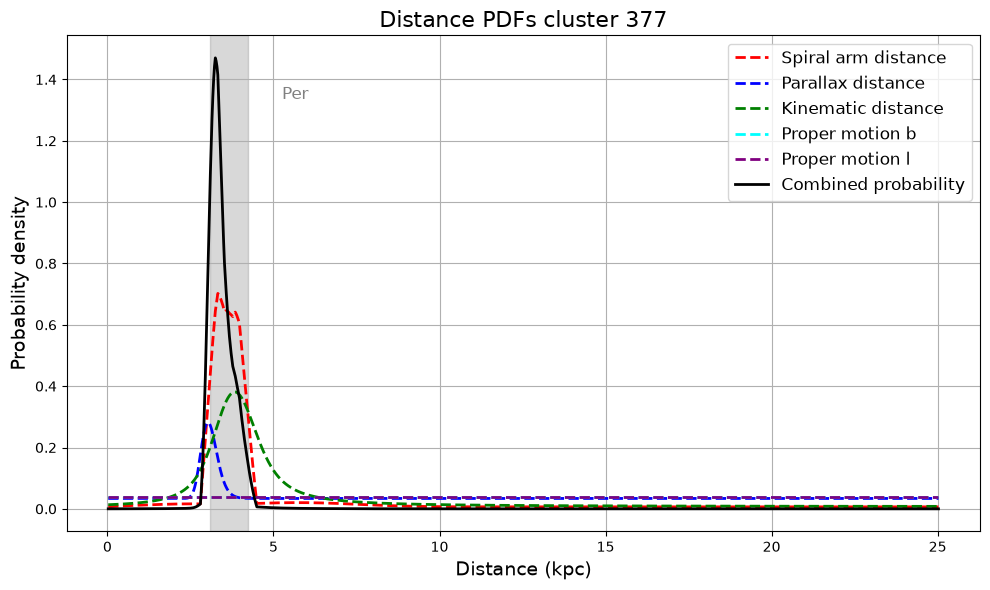

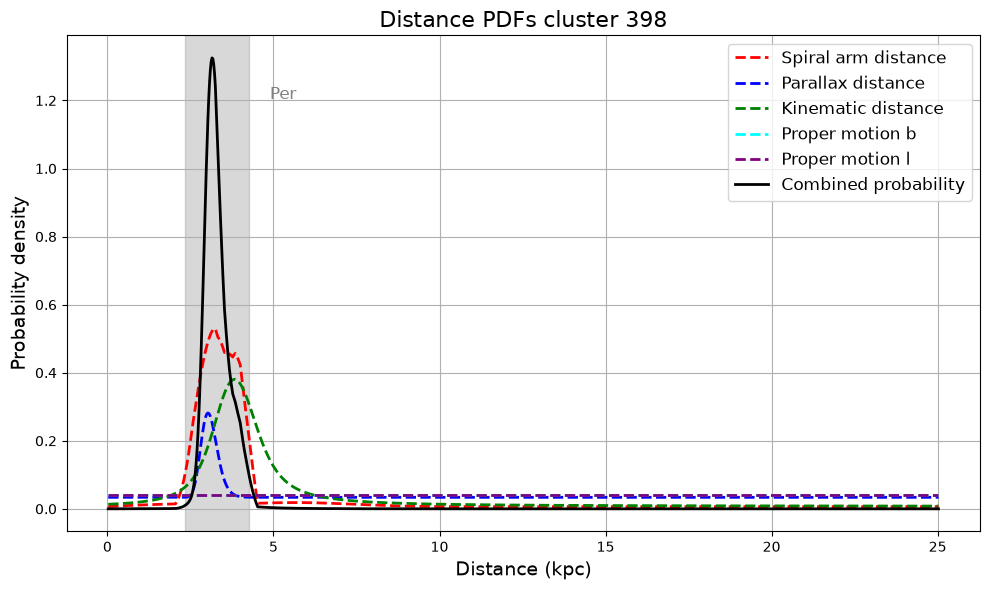

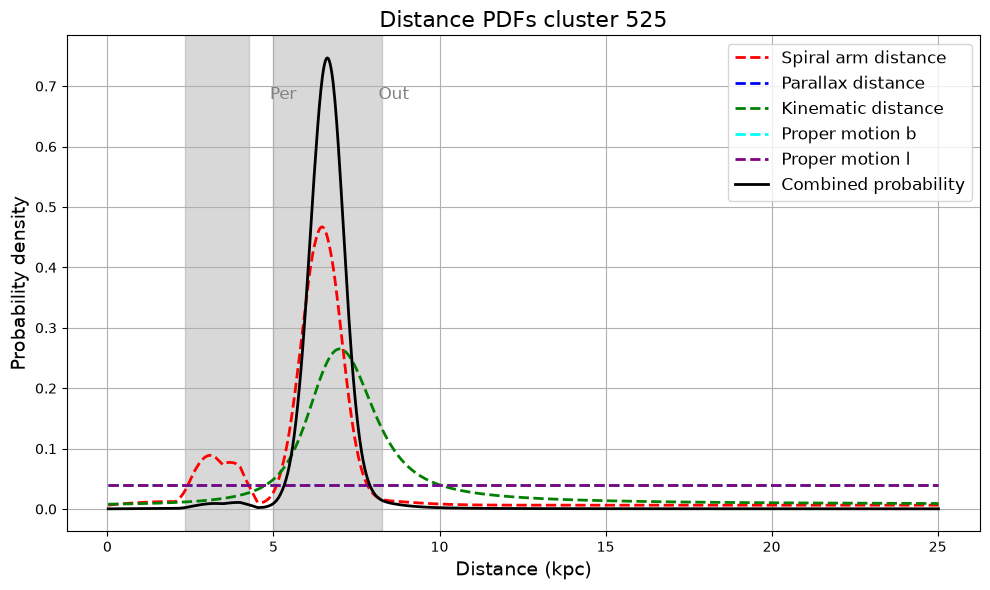

In [65]:
# Plots the distances
# Run fearlessly and optionally

def plot_distance_pdf(cluster_number,distance_dir):

    data_final     = np.loadtxt(distance_dir + f'{cluster_number}_final_distance_pdf.dat', skiprows=2)  # Skip header: "D(kpc) Probability"
    distances1     = data_final[:, 0]   # Column 1: D(kpc)
    probabilities1 = data_final[:, 1]  # Column 2: Probability

    data_spiral    = np.loadtxt(distance_dir + str(cluster_number)+'_arm_latitude_pdf.dat', skiprows=2, usecols=(0, 1))
    distances2     = data_spiral[:, 0]
    probabilities2 = data_spiral[:, 1]

    data_parallax  = np.loadtxt(distance_dir + str(cluster_number)+'_parallaxes_pdf.dat', skiprows=2)
    distances3     = data_parallax[:, 0]
    probabilities3 = data_parallax[:, 1]

    data_kinematic = np.loadtxt(distance_dir + str(cluster_number)+'_kinematic_distance_pdf.dat', skiprows=2)
    distances4     = data_kinematic[:, 0]
    probabilities4 = data_kinematic[:, 1]

    data_latitude  = np.loadtxt(distance_dir + str(cluster_number)+'_pm_bee_distance_pdf.dat', skiprows=2)
    distances5     = data_latitude[:, 0]
    probabilities5 = data_latitude[:, 1]

    data_longitude = np.loadtxt(distance_dir + str(cluster_number)+'_pm_ell_distance_pdf.dat', skiprows=2)
    distances6     = data_longitude[:, 0]
    probabilities6 = data_longitude[:, 1]
    
    arm_ranges = []
    arm_file = distance_dir + str(cluster_number) + '_arm_ranges.dat'
    with open(arm_file, 'r') as f:
        for line in f:
            if line.strip().startswith('!') or not line.strip():
                continue
            parts = line.split()
            start, end, name = float(parts[0]), float(parts[1]), parts[2]
            if start > 0 and end > 0:
                arm_ranges.append((start, end, name))

# Plotting
    plt.figure(figsize=(10, 6))
    
    ymax = max(probabilities1)  # Adjust if you'd rather base it on other curves or overall max

    for start, end, name in arm_ranges:
    # Shading (transparent and no legend entry)
        plt.axvspan(start, end, color='gray', alpha=0.3, zorder=0)

    # Label the spiral arm at the midpoint
        midpoint = (start + end) / 2
        plt.text(midpoint+2, ymax * 0.9, name, fontsize=12, ha='center', va='bottom', color='gray')
    
    plt.plot(distances2, probabilities2, label='Spiral arm distance', color='red', lw=2, linestyle='--')
    plt.plot(distances3, probabilities3, label='Parallax distance', color='blue', lw=2, linestyle='--')
    plt.plot(distances4, probabilities4, label='Kinematic distance', color='green', lw=2, linestyle='--')
    plt.plot(distances5, probabilities5, label='Proper motion b', color='cyan', lw=2, linestyle='--')
    plt.plot(distances6, probabilities6, label='Proper motion l', color='purple', lw=2, linestyle='--')
    plt.plot(distances1, probabilities1, label='Combined probability', color='black', lw=2)

    plt.xlabel('Distance (kpc)', fontsize=14)
    plt.ylabel('Probability density', fontsize=14)
    plt.title(f'Distance PDFs cluster {cluster_number}', fontsize=16)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for id in cluster_ids:
    plot_distance_pdf(id, distance_dir)

In [66]:
# Initialisess stuff
# Run fearlessly

os.chdir(clusters_path)

# Constants
a1, a2, a3 = 1.0077, 0.0394, 0.0071  # Brand & Blitz (1993)
theta0     = 236.0              # km/s
R0         = 8.15               # kpc
omega0     = theta0 / R0
dtor       = pi / 180

# Initialize outputs
n              = len(df)
R              = np.zeros(n)
Vcalc          = np.zeros(n)
d_near         = np.zeros(n)
d_far          = np.zeros(n)
distance       = np.full(n, np.nan)
dist_method    = np.zeros(n, dtype=int)

In [67]:
# Full rotation curve code
# Run fearlessly

# Step 1: Rotation Curve + Near/Far Distance Calculation
for i in range(n):
    l, b, V = df['x_cen'][i], df['y_cen'][i], df['v_cen'][i]/1000
    
    Ri = 0.1
    count = 0
    while True:
        count +=1
        Ri += 0.01
        wi = omega0 * ((a1 * (Ri/R0)**(a2 - 1)) + a3 * (R0 / Ri))
        Vtest = R0 * (wi - omega0) * sin(radians(l)) * cos(radians(b))
        if abs(Vtest - V) < 0.4:
            break

        if count > 1e6:
            count = 0
            Ri = np.nan
            break
    
    R[i] = Ri
    Vcalc[i] = Vtest

    A = cos(radians(b))**2
    B = 2 * R0 * cos(radians(b)) * cos(radians(l))
    C = R0**2 - Ri**2
    delta = B**2 - 4 * A * C

    if delta <= 0:
        d1 = d2 = R0 * cos(radians(l)) / cos(radians(b))
    else:
        sqrt_delta = sqrt(delta)
        d1 = -( -B + sqrt_delta ) / (2 * A)
        d2 = -( -B - sqrt_delta ) / (2 * A)

    d_near[i], d_far[i] = min(d1, d2), max(d1, d2)

    # Outer Galaxy check
    if R[i] >= R0 or d_near[i] <= 0:
        distance[i] = d_far[i]
        dist_method[i] = 2  # Outer Galaxy
    #print(i)

# Step 2: Tangent Point Method
# Apply only to unresolved sources (dist_method = 0)
for i in range(n):
    if dist_method[i] != 0:
        continue
    l = df['x_cen'][i]
    V = df['v_cen'][i]
    tan_vel = theta0 * sin(radians(l))
    if abs(V - tan_vel) < 10 and (d_far[i] - d_near[i]) <= 1.0:
        distance[i] = (d_near[i] + d_far[i]) / 2
        dist_method[i] = 3  # Tangent method

# Step 3: Scale Height Method
# Still unresolved sources
for i in range(n):
    if dist_method[i] != 0:
        continue
    b = df['y_cen'][i]
    z = d_far[i] * 1000 * tan(radians(b))  # pc
    if abs(z) > 120:
        distance[i] = d_near[i]
        dist_method[i] = 4  # Scale height method

# Step 4: Append Results
df['R_GC'] = R
df['d_near'] = d_near
df['d_far'] = d_far
df['distance'] = distance
df['dist_method'] = dist_method

In [68]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,ancestor,n_leaves,structure_type,has_match,AGAL_distance,R_GC,d_near,d_far,distance,dist_method
0,35,15593.850117,27731.0,97.416487,36.755553,169.449503,59.838088,18093.467770,2.836145,233.081490,...,8,5,b'B',False,0,9.17,-11.347918,1.556811,1.556811,2
1,94,691.691716,1422.0,16.992447,9.346709,64.433351,12.602518,21543.475701,2.486464,234.897158,...,94,3,b'T',False,0,9.34,-11.227546,1.853908,1.853908,2
2,255,674.863010,2131.0,15.221981,10.179970,137.858688,12.448266,43347.135113,2.414690,234.201688,...,229,7,b'B',False,0,10.79,-13.295380,3.760884,3.760884,2
3,267,1926.686744,3652.0,24.237503,18.252624,-150.154222,21.033260,43149.256478,2.115020,233.018188,...,267,3,b'T',False,0,10.82,-13.545154,3.739495,3.739495,2
4,318,302.979287,538.0,11.984552,5.804879,84.449455,8.340796,44021.222788,2.255512,234.812838,...,229,2,b'B',False,0,10.81,-13.210543,3.817679,3.817679,2
5,377,1506.527231,3796.0,33.170746,10.428547,145.749249,18.598997,46874.355037,2.245387,234.692391,...,377,6,b'T',False,0,11.04,-13.523830,4.101840,4.101840,2
6,398,2207.281608,3568.0,42.325632,11.974472,55.418533,22.512820,46806.564082,2.407123,234.484270,...,398,6,b'T',False,0,11.04,-13.560798,4.090606,4.090606,2
7,525,1852.138419,3130.0,29.070286,14.629389,120.287684,20.622331,76301.998690,2.460994,234.316965,...,525,6,b'T',False,0,13.99,-17.080468,7.571603,7.571603,2


In [69]:
# Function definition
# Run fearlessly

def determine_distance_assignment(txt_path, d_near, d_far):
    components = []

    with open(txt_path, 'r') as f:
        lines = f.readlines()

    # Filter lines that contain "Probability component"
    prob_lines = [line.strip() for line in lines if line.strip().startswith("Probability component")]

    for line in prob_lines:
        parts = line.split()
        try:
            dist = float(parts[3])
            prob = float(parts[5])
            components.append((dist, prob))
        except (IndexError, ValueError):
            continue

    if not components:
        raise ValueError("No valid probability components found.")

    # Get distance of component with highest probability
    best_dist, _ = max(components, key=lambda x: x[1])
    
    all_distances = [comp[0] for comp in components]
    min_distance = min(all_distances)
    max_distance = max(all_distances)

    if abs(best_dist - d_near) <= abs(best_dist - d_far):
            return 'near'
    else:
            return 'far'

prt_dir = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'  # Update if needed
final_distances = []
distance_flags = []  # Optional: stores 'near' or 'far'

In [70]:
# Selects near or far distances
# Run fearlessly

for idx, row in df.iterrows():
    obj_id = int(row['_idx'])
    prt_file = os.path.join(prt_dir, f"{obj_id}.prt")

    if row['R_GC'] < R0:

        try:
            choice = determine_distance_assignment(prt_file, row['d_near'], row['d_far'])
            if choice == 'near':
                final_distances.append(row['d_near'])
                distance_flags.append('near')
            else:
                final_distances.append(row['d_far'])
                distance_flags.append('far')
        except Exception as e:
            print(f"Warning: Failed to process {prt_file} due to {e}")


            if row['d_near'] < 0:
                if row['d_far'] > 0:
                    final_distances.append(row['d_far'])
                    distance_flags.append('far')
                elif row['d_far'] < 0:
                    final_distances.append(min(abs(row['d_near']), abs(row['d_far'])))
                    distance_flags.append('near')
                

    else:
        final_distances.append(row['d_far'])
        distance_flags.append('No_KDA')

df['distance'] = final_distances
df['distance_flag'] = distance_flags  # Optional for debugging
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,n_leaves,structure_type,has_match,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag
0,35,15593.850117,27731.0,97.416487,36.755553,169.449503,59.838088,18093.467770,2.836145,233.081490,...,5,b'B',False,0,9.17,-11.347918,1.556811,1.556811,2,No_KDA
1,94,691.691716,1422.0,16.992447,9.346709,64.433351,12.602518,21543.475701,2.486464,234.897158,...,3,b'T',False,0,9.34,-11.227546,1.853908,1.853908,2,No_KDA
2,255,674.863010,2131.0,15.221981,10.179970,137.858688,12.448266,43347.135113,2.414690,234.201688,...,7,b'B',False,0,10.79,-13.295380,3.760884,3.760884,2,No_KDA
3,267,1926.686744,3652.0,24.237503,18.252624,-150.154222,21.033260,43149.256478,2.115020,233.018188,...,3,b'T',False,0,10.82,-13.545154,3.739495,3.739495,2,No_KDA
4,318,302.979287,538.0,11.984552,5.804879,84.449455,8.340796,44021.222788,2.255512,234.812838,...,2,b'B',False,0,10.81,-13.210543,3.817679,3.817679,2,No_KDA
5,377,1506.527231,3796.0,33.170746,10.428547,145.749249,18.598997,46874.355037,2.245387,234.692391,...,6,b'T',False,0,11.04,-13.523830,4.101840,4.101840,2,No_KDA
6,398,2207.281608,3568.0,42.325632,11.974472,55.418533,22.512820,46806.564082,2.407123,234.484270,...,6,b'T',False,0,11.04,-13.560798,4.090606,4.090606,2,No_KDA
7,525,1852.138419,3130.0,29.070286,14.629389,120.287684,20.622331,76301.998690,2.460994,234.316965,...,6,b'T',False,0,13.99,-17.080468,7.571603,7.571603,2,No_KDA


In [71]:
# Initialise stuff and 
# Run fearlessly        
# --- Get the numbers of the clusters we work with ---
cluster_numbers = df['_idx']


with fits.open(mult_filename) as hdul:
    raw_data = hdul[0].data


# --- Load COLTE densities ---
has_COLTE = False
try:
    if os.path.exists(COLTE_N13_file):
        with fits.open(COLTE_N13_file) as hdul_COLTE_N13:
            data_COLTE_N13 = hdul_COLTE_N13[0].data
            header_COLTE_N13 = hdul_COLTE_N13[0].header
        has_COLTE = True
    else:
        raise FileNotFoundError
except FileNotFoundError:
    print(f"Warning: {COLTE_N13_file} not found. Using all-True mask.")
    # Create a dummy all-True mask of compatible shape
    # You must already have a known shape, e.g., from another array
    colte_masked = np.ones_like(raw_data, dtype=bool)

In [539]:
## X-factor masses
has_COLTE = False

nonzero_pixels = []
total_flux     = []
COLTE_Mass     = []

for num in cluster_numbers:
    if num == 0:
        new_data = np.where(mask, 1, 0) # Replace cluster 0 voxels with 1, keep background (-1) untouched
    if has_COLTE == False:
        mask = (data == num)
    else:
        mask = (data == num) & (~np.isnan(data_COLTE_N13))
    new_data = np.where(mask, raw_data, 0)


    if has_COLTE:
        # Only calculate COLTE-based mass if we have the file
        colte_masked = np.where(mask, data_COLTE_N13, 0)
        colte_mass   = np.nansum(colte_masked) * np.abs(CDELT3)
        if header_COLTE_N13['CUNIT3'] == 'm/s':
            colte_mass = colte_mass / 1000
    else:
        colte_mass = 0

    new_data_good = new_data[~np.isnan(new_data)]
    pixels_nonzero = np.count_nonzero(new_data_good)
    integ_flux = np.sum(new_data_good) * np.abs(CDELT3)
    if np.abs(CDELT3) > 100:
            integ_flux = integ_flux / 1000

    print(num)
    COLTE_Mass.append(colte_mass)

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    print("cluster pixels sum:", new_data.sum()) 
    print("integrated flux:", integ_flux)
    print("number of pixels:", pixels_nonzero)
    print("colte total density:", colte_mass)

32
cluster pixels sum: 34388.57
integrated flux: 22352.5706957861
number of pixels: 4939
colte total density: 0
64
cluster pixels sum: 151491.33
integrated flux: 98469.36324892008
number of pixels: 26182
colte total density: 0
120
cluster pixels sum: 45854.35
integrated flux: 29805.328505839178
number of pixels: 7673
colte total density: 0
133
cluster pixels sum: 1.5671306e+06
integrated flux: 1018634.9059155572
number of pixels: 116092
colte total density: 0
425
cluster pixels sum: 1.5671128e+06
integrated flux: 1018623.287165561
number of pixels: 331502
colte total density: 0
488
cluster pixels sum: 3.3869812e+06
integrated flux: 2201537.811777181
number of pixels: 271485
colte total density: 0
708
cluster pixels sum: 813263.6
integrated flux: 528621.3560764405
number of pixels: 128152
colte total density: 0
808
cluster pixels sum: 47779.164
integrated flux: 31056.4566304284
number of pixels: 6783
colte total density: 0
905
cluster pixels sum: 28636.201
integrated flux: 18613.5307556

In [72]:
## LTE masses

nonzero_pixels = []
total_flux     = []
COLTE_Mass     = []

for num in cluster_numbers:
    mask = (data == num)
    new_data = np.where(mask, raw_data, 0)

    # Only calculate COLTE-based mass if we have the file
    colte_masked = np.where(mask, data_COLTE_N13, 0)
    colte_mass   = np.nansum(colte_masked) * np.abs(header_COLTE_N13['CDELT3'])
    if header_COLTE_N13['CUNIT3'] == 'm/s':
            colte_mass = colte_mass / 1000


    new_data_good = colte_masked[~np.isnan(colte_masked)]
    pixels_nonzero = np.count_nonzero(new_data_good)
    integ_flux = np.sum(new_data_good) * CDELT3

    if header['CUNIT3'] == 'm/s':
        integ_flux = integ_flux / 1000

    print(num)

    total_flux.append(integ_flux)
    nonzero_pixels.append(pixels_nonzero)
    COLTE_Mass.append(colte_mass)
    print("cluster pixels sum:", new_data.sum())
    print("integrated flux:", integ_flux)
    print("number of pixels:", pixels_nonzero)
    print("colte total density:", colte_mass)

# Append the columns to the df and verify it

df['total_flux']   = total_flux # actually integrated
df['pixel_number'] = nonzero_pixels 
df['COLTE_Density']   = COLTE_Mass
df

35
cluster pixels sum: 249918.52
integrated flux: 3.772271432925344e+19
number of pixels: 58824
colte total density: 3.772271432925344e+19
94
cluster pixels sum: 9859.656
integrated flux: 1.3786398008658196e+18
number of pixels: 2012
colte total density: 1.3786398008658196e+18
255
cluster pixels sum: 31042.953
integrated flux: 3.8802502104417495e+18
number of pixels: 6905
colte total density: 3.880250210441749e+18
267
cluster pixels sum: 30400.525
integrated flux: 4.141425717172175e+18
number of pixels: 8631
colte total density: 4.141425717172175e+18
318
cluster pixels sum: 9073.028
integrated flux: 7.292538278756105e+17
number of pixels: 1359
colte total density: 7.292538278756105e+17
377
cluster pixels sum: 117914.95
integrated flux: 1.2833189441116981e+19
number of pixels: 16201
colte total density: 1.2833189441116981e+19
398
cluster pixels sum: 40758.184
integrated flux: 4.951527111042353e+18
number of pixels: 7777
colte total density: 4.951527111042353e+18
525
cluster pixels sum: 

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag,total_flux,pixel_number,COLTE_Density
0,35,15593.850117,27731.0,97.416487,36.755553,169.449503,59.838088,18093.467770,2.836145,233.081490,...,0,9.17,-11.347918,1.556811,1.556811,2,No_KDA,3.772271e+19,58824,3.772271e+19
1,94,691.691716,1422.0,16.992447,9.346709,64.433351,12.602518,21543.475701,2.486464,234.897158,...,0,9.34,-11.227546,1.853908,1.853908,2,No_KDA,1.378640e+18,2012,1.378640e+18
2,255,674.863010,2131.0,15.221981,10.179970,137.858688,12.448266,43347.135113,2.414690,234.201688,...,0,10.79,-13.295380,3.760884,3.760884,2,No_KDA,3.880250e+18,6905,3.880250e+18
3,267,1926.686744,3652.0,24.237503,18.252624,-150.154222,21.033260,43149.256478,2.115020,233.018188,...,0,10.82,-13.545154,3.739495,3.739495,2,No_KDA,4.141426e+18,8631,4.141426e+18
4,318,302.979287,538.0,11.984552,5.804879,84.449455,8.340796,44021.222788,2.255512,234.812838,...,0,10.81,-13.210543,3.817679,3.817679,2,No_KDA,7.292538e+17,1359,7.292538e+17
5,377,1506.527231,3796.0,33.170746,10.428547,145.749249,18.598997,46874.355037,2.245387,234.692391,...,0,11.04,-13.523830,4.101840,4.101840,2,No_KDA,1.283319e+19,16201,1.283319e+19
6,398,2207.281608,3568.0,42.325632,11.974472,55.418533,22.512820,46806.564082,2.407123,234.484270,...,0,11.04,-13.560798,4.090606,4.090606,2,No_KDA,4.951527e+18,7777,4.951527e+18
7,525,1852.138419,3130.0,29.070286,14.629389,120.287684,20.622331,76301.998690,2.460994,234.316965,...,0,13.99,-17.080468,7.571603,7.571603,2,No_KDA,3.516887e+18,8474,3.516887e+18


In [73]:
df['total_flux']   = total_flux # actually integrated
df['pixel_number'] = nonzero_pixels 
df['COLTE_Density']   = COLTE_Mass
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,AGAL_distance,R_GC,d_near,d_far,distance,dist_method,distance_flag,total_flux,pixel_number,COLTE_Density
0,35,15593.850117,27731.0,97.416487,36.755553,169.449503,59.838088,18093.467770,2.836145,233.081490,...,0,9.17,-11.347918,1.556811,1.556811,2,No_KDA,3.772271e+19,58824,3.772271e+19
1,94,691.691716,1422.0,16.992447,9.346709,64.433351,12.602518,21543.475701,2.486464,234.897158,...,0,9.34,-11.227546,1.853908,1.853908,2,No_KDA,1.378640e+18,2012,1.378640e+18
2,255,674.863010,2131.0,15.221981,10.179970,137.858688,12.448266,43347.135113,2.414690,234.201688,...,0,10.79,-13.295380,3.760884,3.760884,2,No_KDA,3.880250e+18,6905,3.880250e+18
3,267,1926.686744,3652.0,24.237503,18.252624,-150.154222,21.033260,43149.256478,2.115020,233.018188,...,0,10.82,-13.545154,3.739495,3.739495,2,No_KDA,4.141426e+18,8631,4.141426e+18
4,318,302.979287,538.0,11.984552,5.804879,84.449455,8.340796,44021.222788,2.255512,234.812838,...,0,10.81,-13.210543,3.817679,3.817679,2,No_KDA,7.292538e+17,1359,7.292538e+17
5,377,1506.527231,3796.0,33.170746,10.428547,145.749249,18.598997,46874.355037,2.245387,234.692391,...,0,11.04,-13.523830,4.101840,4.101840,2,No_KDA,1.283319e+19,16201,1.283319e+19
6,398,2207.281608,3568.0,42.325632,11.974472,55.418533,22.512820,46806.564082,2.407123,234.484270,...,0,11.04,-13.560798,4.090606,4.090606,2,No_KDA,4.951527e+18,7777,4.951527e+18
7,525,1852.138419,3130.0,29.070286,14.629389,120.287684,20.622331,76301.998690,2.460994,234.316965,...,0,13.99,-17.080468,7.571603,7.571603,2,No_KDA,3.516887e+18,8474,3.516887e+18


In [74]:
# Chooses between AGAL distance for clusters with matches and best distance for those without
# Looks like AGAL distances are strings! turn them to floats first.
# Run fearlessly

final_distance = []
for i in range(len(df)):
    if df['has_match'][i] and df['AGAL_distance'][i] != '---':
        final_distance.append(float(df['AGAL_distance'][i]))
    else:
        final_distance.append(df['distance'][i])

df['final_distance'] = final_distance

In [75]:
# Spreadsheet calculations
# Run fearlesly

df['distance_cm'] = df['distance'] * 3.086 * pow(10,21)
df['Mean_flux']   = df['total_flux'] / df['pixel_number'] # actually integrated, not mean

# Constants
X_factor = 2 * pow(10,20)  # 3.05 for Inner FGN
    
mH2            = 1.67 * 2.72 * pow(10,-24)
Msol           = 2 * pow(10,33)
pixel_area_arc = pow((np.abs(header['CDELT1']) * 3600),2)
arc_2_sr       = pow(np.pi/180/3600,2)

df['density']=X_factor*df['Mean_flux']

# Pixel area masses
df['angular_size_sr']       = df['pixel_number'] * pixel_area_arc * arc_2_sr
df['area_cm2_pixel_method'] = df['angular_size_sr'] * pow(df['distance_cm'],2)
df['NH2_pixel']             = df['area_cm2_pixel_method'] * df['density']
df['M_pixel_g']             = df['NH2_pixel'] * mH2

df['M_pixel_Sol']   = df['M_pixel_g'] / Msol
df['M_COLTE_Sol_CO']   = df['COLTE_Density'] / Msol * pixel_area_arc * arc_2_sr * pow(df['distance_cm'],2) * mH2
df['M_COLTE_Sol_H2']   = df['M_COLTE_Sol_CO'] / (8.5 / 10 ** 5) * (6.2 * df['R_GC'] + 18.7) 

In [76]:
# Formatting the df
# Run fearlessly

df['area_ellipse']   = df['area_ellipse'].round(1)  # Round to 1 decimal place
df['area_exact']     = df['area_exact'].round(1)
df['major_sigma']    = df['major_sigma'].round(1)
df['minor_sigma']    = df['minor_sigma'].round(1)
df['position_angle'] = df['position_angle'].round(1)
df['radius']         = df['radius'].round(1)
df['v_cen']          = df['v_cen'].round(2)
df['v_rms']          = df['v_rms'].round(2)
df['x_cen']          = df['x_cen'].round(3)
df['y_cen']          = df['y_cen'].round(3)
df['radius_arcsec']  = df['radius_arcsec'].round(1)
df['sigv_kms']       = df['sigv_kms'].round(2)
df['xcens']          = df['xcens'].round(3)
df['ycens']          = df['ycens'].round(3)
df['vcens']          = df['vcens'].round(3)
df['major_arcsec']   = df['major_arcsec'].round(1)
df['minor_arcsec']   = df['minor_arcsec'].round(1)
df['R_GC']           = df['R_GC'].round(2)
df['d_near']         = df['d_near'].round(2)
df['d_far']          = df['d_far'].round(2)
df['distance']       = df['distance'].round(2)
df['final_distance'] = df['final_distance'].round(2)


df['distance_cm']           = df['distance_cm'].apply(lambda x: f'{x:.2e}') # Write to format 1e7
df['Mean_flux']             = df['Mean_flux'].round(2)
df['density']               = df['density'].apply(lambda x: f'{x:.2e}')
df['angular_size_sr']       = df['angular_size_sr'].apply(lambda x: f'{x:.2e}')
df['area_cm2_pixel_method'] = df['area_cm2_pixel_method'].apply(lambda x: f'{x:.2e}')
df['NH2_pixel']             = df['NH2_pixel'].apply(lambda x: f'{x:.2e}')
df['M_COLTE_Sol_CO']        = df['M_COLTE_Sol_CO'].apply(lambda x: f'{x:.2e}')
df['COLTE_Density']         = df['COLTE_Density'].apply(lambda x: f'{x:.2e}')
df['M_pixel_g']             = df['M_pixel_g'].apply(lambda x: f'{x:.2e}')
df['M_pixel_Sol']           = df['M_pixel_Sol'].apply(lambda x: f'{x:.2e}')

In [77]:
# Save final result with proper structure types
if has_COLTE == True:
    csv_output = csv_output.replace("vrms_3_X_factor_masses_spline.csv", "COLTE masses.csv")
df.to_csv(csv_output, index= False)

In [78]:
df

,_idx,area_ellipse,area_exact,major_sigma,minor_sigma,position_angle,radius,v_cen,v_rms,x_cen,...,distance_cm,Mean_flux,density,angular_size_sr,area_cm2_pixel_method,NH2_pixel,M_pixel_g,M_pixel_Sol,M_COLTE_Sol_CO,M_COLTE_Sol_H2
0,35,15593.9,27731.0,97.4,36.8,169.4,59.8,18093.47,2.84,233.081,...,4.80e+21,6.412810e+14,1.28e+35,9.99e-05,2.31e+39,2.96e+74,1.34e+51,6.72e+17,3.36e-03,2985.027244
1,94,691.7,1422.0,17.0,9.3,64.4,12.6,21543.48,2.49,234.897,...,5.72e+21,6.852086e+14,1.37e+35,3.42e-06,1.12e+38,1.53e+73,6.96e+49,3.48e+16,1.74e-04,156.861788
2,255,674.9,2131.0,15.2,10.2,137.9,12.4,43347.14,2.41,234.202,...,1.16e+22,5.619479e+14,1.12e+35,1.17e-05,1.58e+39,1.78e+74,8.06e+50,4.03e+17,2.02e-03,2030.108271
3,267,1926.7,3652.0,24.2,18.3,-150.2,21.0,43149.26,2.12,233.018,...,1.15e+22,4.798315e+14,9.60e+34,1.47e-05,1.95e+39,1.87e+74,8.51e+50,4.25e+17,2.13e-03,2146.831504
4,318,303.0,538.0,12.0,5.8,84.4,8.3,44021.22,2.26,234.813,...,1.18e+22,5.366106e+14,1.07e+35,2.31e-06,3.20e+38,3.44e+73,1.56e+50,7.81e+16,3.90e-04,393.718441
5,377,1506.5,3796.0,33.2,10.4,145.7,18.6,46874.36,2.25,234.692,...,1.27e+22,7.921233e+14,1.58e+35,2.75e-05,4.41e+39,6.98e+74,3.17e+51,1.59e+18,7.93e-03,8131.398560
6,398,2207.3,3568.0,42.3,12.0,55.4,22.5,46806.56,2.41,234.484,...,1.26e+22,6.366886e+14,1.27e+35,1.32e-05,2.10e+39,2.68e+74,1.22e+51,6.09e+17,3.04e-03,3120.238271
7,525,1852.1,3130.0,29.1,14.6,120.3,20.6,76302.00,2.46,234.317,...,2.34e+22,4.150209e+14,8.30e+34,1.44e-05,7.86e+39,6.52e+74,2.96e+51,1.48e+18,7.41e-03,9186.436667


KstestResult(statistic=np.float64(0.03979132781949683), pvalue=np.float64(0.5651616155975692), statistic_location=np.float64(37200.0), statistic_sign=np.int8(-1))


Text(0, 0.5, 'Mass CDF')

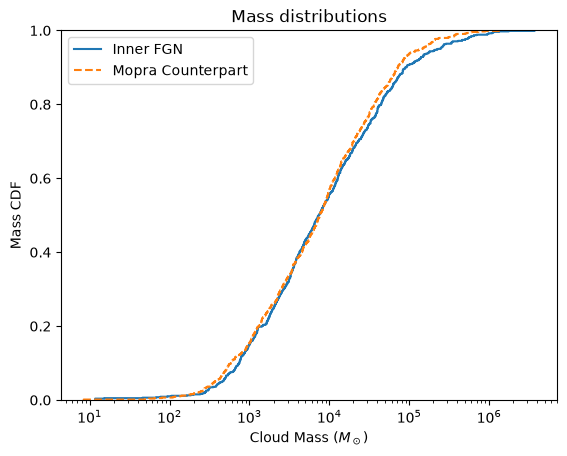

In [79]:
saveplot = False

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/FUGIN_data/13CO/Inner_FGN_13CO_X_factor_Mass_Catalogue.csv')
#df_3 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/FUGIN_data/12CO/Inner_FGN_12CO_X_factor_catalogue.csv')
df_3 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/13CO/Mopra_Full_Cloud_Catalogue_cleaned.csv')


m  = df_2['M_pixel_Sol']
#m2 = df_3['M_pixel_Sol']  # FGN
m2 = df_3['M_13CO_X_Sol']  # Full Mopra
df_M = df_3[(df_3['x_cen'] > 310) & (df_3['x_cen'] < 350)]
m3 = df_M['M_13CO_X_Sol']

print(stats.kstest(m, m3))


plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label="Inner FGN",
    linestyle='-'
)

sns.ecdfplot(
    m3,
    log_scale=True,
    label="Mopra Counterpart",
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')

1.8482587064676617
KstestResult(statistic=np.float64(0.055198973042362), pvalue=np.float64(0.18620855222816235), statistic_location=np.float64(3250.0), statistic_sign=np.int8(-1))
m = 0.9858188180058611*m2 + 0.13039845083218746


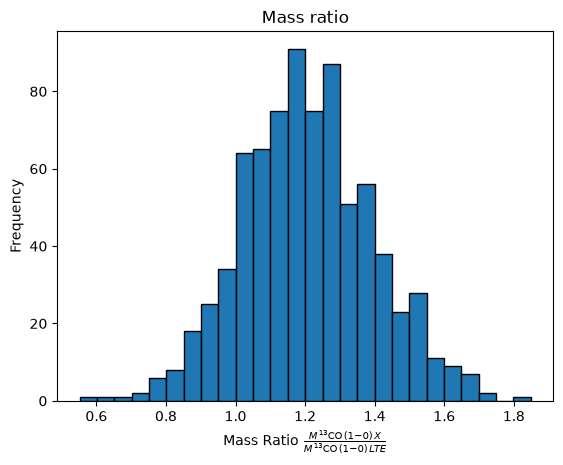

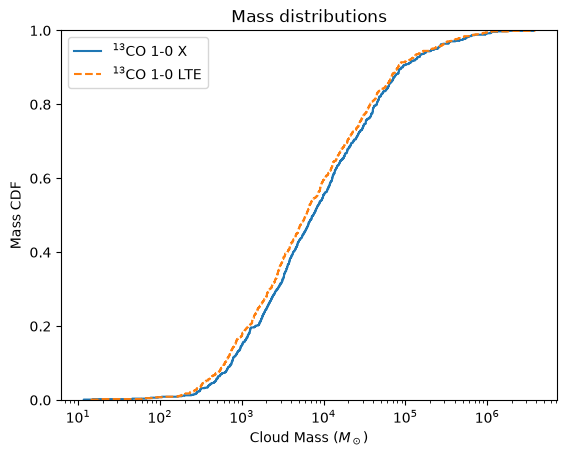

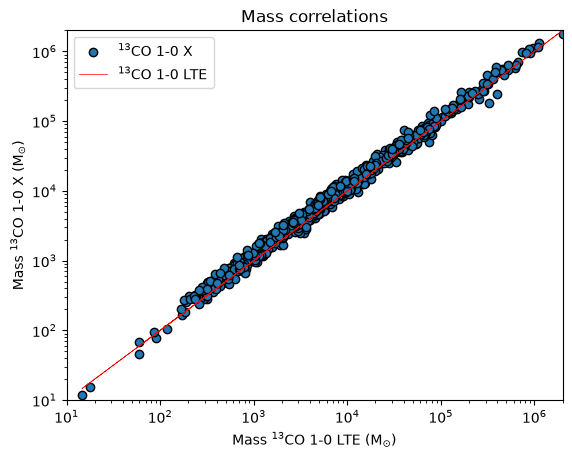

In [60]:
## Copied from BDC, I will use this to compare Mopra full X-factor vs Mopra full COLTE.


saveplot = False

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/FUGIN_data/13CO/Inner_FUGIN_Mass_catalogue_complete.csv')

mass_options = {
    1 : {
        "m2_col": "M_LTE_Sol",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,LTE}$",
        "plottitles": 'Inner_FUGIN_LTE_snr0.png',
        "labels": r"$^{13}$CO 1-0 LTE",
        "axlabel": 'Mass $^{13}$CO 1-0 LTE (M$_{\odot}$)',
        "KStitles": "Inner_FGN_mass_LTE_snr0_KSTest.png",
        "title":'Mass_comparison_LTE_snr0.png'
    },

    2 : {
        "m2_col": "M_pixel_Sol_12",
        "xlabel": r"$\frac{M\,^{13}\mathrm{CO}\,(1\!-\!0)\,X}{M\,^{12}\mathrm{CO}\,(1\!-\!0)\,X}$",
        "plottitles": 'Inner_FGN_mass_12CO_X.png',
        "labels": r"$^{12}$CO 1-0 X",
        "axlabel": 'Mass $^{12}$CO 1-0 X (M$_{\odot}$)',
        "KStitles": "Inner_FGN_mass_12CO_KSTest.png",
        "title":'Mass_comparison_12CO.png'
    }
}


mode = 1


m = df_2['M_pixel_Sol_13'].dropna()

m2 = df_2[mass_options[mode]['m2_col']].dropna()

mask = (m>0) & (m2 >0)

m  = m[mask]
m2 = m2[mask]


equal_ratio = m / m2

mask2 = (equal_ratio < equal_ratio.max() +1)

equal_ratio = equal_ratio[mask2]
m = m[mask2]
m2 = m2[mask2]



bins = np.linspace(
equal_ratio.min(),
equal_ratio.max(),
int(np.sqrt(len(equal_ratio)))
)

plt.hist(equal_ratio, bins=bins, edgecolor='k')



plt.xlabel(f'Mass Ratio {mass_options[mode]["xlabel"]}')
plt.ylabel('Frequency')
plt.title(r'Mass ratio')

print(equal_ratio.max())

if saveplot == True:
    plt.savefig(mass_options[mode]['plottitles'])

print(stats.kstest(m, m2))

coeffs = np.polyfit(np.log10(m2), np.log10(m), 1)
slope = coeffs[0]
intercept = coeffs[1]
print(f"m = {slope}*m2 + {intercept}")


plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label=r"$^{13}$CO 1-0 X",
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label=mass_options[mode]['labels'],
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')
if saveplot == True:
    plt.savefig(mass_options[mode]['KStitles'])


label_choice = mass_options[mode]["labels"]
axlabel      = mass_options[mode]["axlabel"]

plt.figure()
plt.scatter(
    m2,
    m,
    edgecolor='k',
    label = r"$^{13}$CO 1-0 X")
plt.plot(
    m2,
    m2,
    color='red',
    label = label_choice,
    linewidth = 0.5
)
plt.ylabel('Mass $^{13}$CO 1-0 X (M$_{\odot}$)')
plt.xlabel(axlabel)
plt.xscale('log')
plt.xlim([10, 2000000])
plt.ylim([10, 2000000])
plt.yscale('log')
plt.title('Mass correlations')
plt.legend()

file_title = mass_options[mode]["title"]
if saveplot == True:
    plt.savefig(mass_options[mode]['title'])

KstestResult(statistic=np.float64(0.09523809523809523), pvalue=np.float64(0.9999961038154768), statistic_location=np.float64(2100.0), statistic_sign=np.int8(1))


Text(0, 0.5, 'Mass CDF')

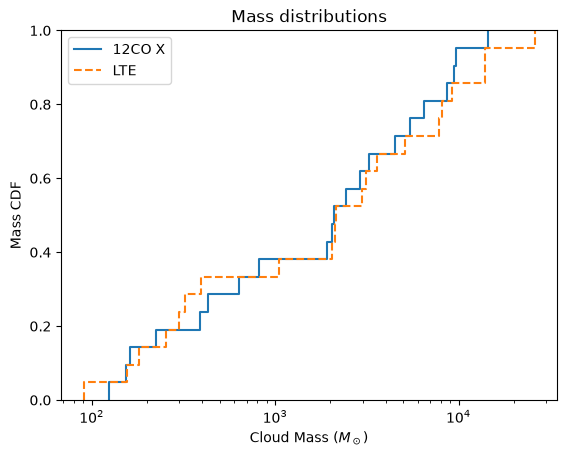

In [82]:
saveplot = False

df_2 = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/FGN/12CO/Outer_FGN_cloud_catalogue_complete.csv')


m  = df_2['M_pixel_Sol']
m2 = df_2['M_COLTE_Sol_H2']


mask = (m >0) & (m2 > 0)

m  = m[mask]
m2 = m2[mask]

print(stats.kstest(m, m2))


plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label="12CO X",
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label="LTE",
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')